In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm
import json

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [2]:
def matching(ref_library, spectra_data_ir, limits, lib_name, data_name):
    
    lim1, lim2 = limits

    wn_gl = np.array(spectra_data_ir.columns[:-4])

    idx_gl = list(np.logical_or(np.logical_and(wn_gl > lim1[0], wn_gl < lim1[1]),
                           np.logical_and(wn_gl > lim2[0], wn_gl < lim2[1])
                          ) ) + [False]*4


    wn_fl = np.array(ref_library.columns[:-4])

    idx_fl = list(np.logical_or(np.logical_and(wn_fl > lim1[0], wn_fl < lim1[1]),
                                np.logical_and(wn_fl > lim2[0], wn_fl < lim2[1])
                                )) + [False]*4
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
    y_train_ir = ref_library.iloc[:,-2]


    x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
    x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')
    
    pred_ = corr_matching(x_train_ir, y_train_ir, 
                          x_test_ir, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    pred_df = pred_df.reset_index(drop=True) 
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df['id'] = spectra_data_ir['id']
    pred_df['background_'+data_name] = spectra_data_ir['background']
    pred_df[hqi_name] = pred_hqi
    
    
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [3]:
flopp_df_trans = pd.read_csv('gloves_contamination/flopp_data_ir_final_transmission.csv')
del flopp_df_trans['Unnamed: 0']

flopp_df = pd.read_csv('gloves_contamination/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)

rebecca_df = pd.read_csv('gloves_contamination/rebecca_data_ir_final.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)

stearates_df = pd.read_csv('gloves_contamination/stearates_data_ir_final.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])

gloves_data_ir = pd.read_csv('gloves_contamination/gloves_data_ir_final.csv')
del gloves_data_ir['Unnamed: 0']
gloves_data_ir.columns = list(np.float64(gloves_data_ir.columns[:-4])) + list(gloves_data_ir.columns[-4:])
gloves_data_ir = gloves_data_ir.query('background == "no_background"').reset_index(drop=True)

ids_flopp = np.unique(flopp_df_trans.query('data_source == "flopp"')['id'])
ids_flopp_e = np.unique(flopp_df_trans.query('data_source == "flopp_e"')['id'])
ids_rebecca = np.unique(rebecca_df['id'])
ids_stearates = np.unique(stearates_df['id'])

In [4]:
all_df = pd.concat([stearates_df, rebecca_df], axis=0).reset_index(drop=True)
labels_reb_stearates = np.concatenate([np.unique(stearates_df['polymer']),
                                             np.unique(rebecca_df['polymer'])])

labels_reb_stearates = np.array(pd.DataFrame({'label':labels_reb_stearates,
                                                  'a':[1*('Stearate' not in x) for x in labels_reb_stearates]}).sort_values(['a', 'label'])['label'])

In [5]:
mat_list = []
acc_list = []
for i in trange(100):
    np.random.seed(i)
    train_df_list = []
    test_df_list = []
    for p in np.unique(all_df['polymer']):
        all_df_aux = all_df.query('polymer == @p').reset_index(drop=True)
        n = all_df_aux.shape[0]
        idx = np.arange(n)
        np.random.shuffle(idx)
        train_df_list.append(all_df_aux.iloc[idx[:int(n/2)],:])
        test_df_list.append(all_df_aux.iloc[idx[int(n/2):],:])

    reference_lib = pd.concat(train_df_list, axis=0).reset_index(drop=True)
    test_df = pd.concat(test_df_list, axis=0).reset_index(drop=True)
    polymer_test = np.array(test_df['polymer'])
    test_df = test_df.drop('polymer', axis=1)
    test_df['background'] = 'no_background'

    pred_df = matching(reference_lib, test_df, limits=((980,1800),(2720, 2970)), lib_name='ref', data_name='final')
    polymer_pred = np.array(pred_df[0]['polymer_ref'])
    
    idx_match = pred_df[0]['hqi_ref']>=.7
    acc_list.append(np.mean(polymer_test[idx_match] == polymer_pred[idx_match]))
    
    mat = confusion_matrix(polymer_test[idx_match], 
                           polymer_pred[idx_match],
                           labels=labels_reb_stearates)
    mat_list.append(mat)

100%|█████████████████████████████████████████| 100/100 [00:09<00:00, 10.70it/s]


In [9]:
mean_mat = np.mean(mat_list,0)
np.mean(acc_list)

0.8970744680851063

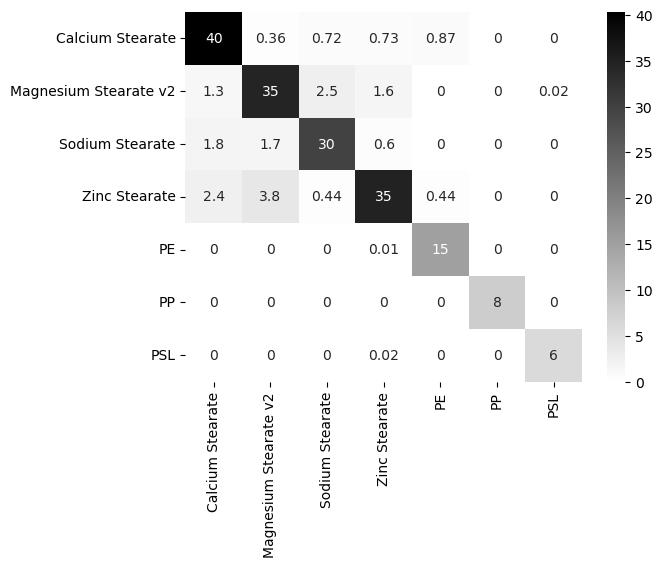

In [10]:
_ = sns.heatmap(mean_mat, 
                #annot=True,
                yticklabels=labels_reb_stearates, 
                xticklabels=labels_reb_stearates,
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':10})
_ = plt.savefig('gloves_contamination/false_negative_analysis/conf_matrix_ir_count.png',bbox_inches='tight')

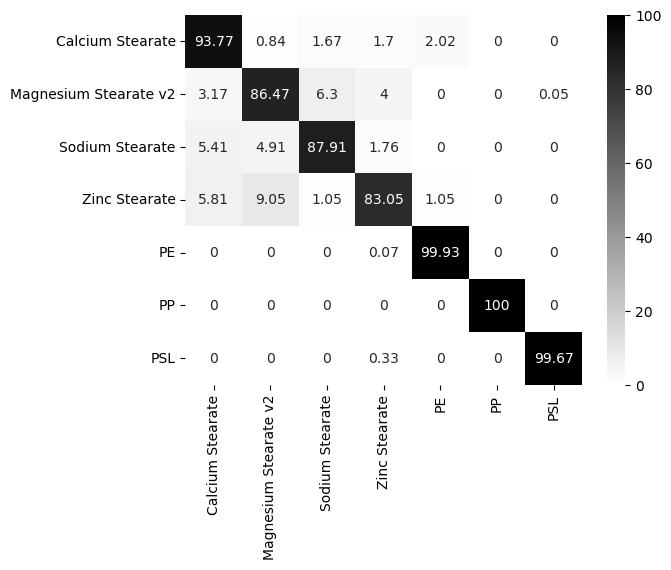

In [11]:
_ = sns.heatmap(np.round(100*mean_mat / mean_mat.sum(1)[:,None], 2), 
                #annot=True,
                yticklabels=labels_reb_stearates, 
                xticklabels=labels_reb_stearates,
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':10},
                fmt=".4g",)
_ = plt.savefig('gloves_contamination/false_negative_analysis/conf_matrix_ir_percentage.png',bbox_inches='tight')

In [12]:
df_mat = pd.DataFrame(mean_mat)
df_mat.columns = labels_reb_stearates
df_mat.index = labels_reb_stearates
df_mat.to_csv('gloves_contamination/false_negative_analysis/conf_matrix_ir_count.csv')

In [13]:
np.round(100*df_mat / df_mat.sum(1)[:,None], 2).to_csv('gloves_contamination/false_negative_analysis/conf_matrix_ir_percentage.csv')


In [14]:
def matching_r(ref_library, spectra_data_ir, limits, lib_name, data_name):
    
    lim1, lim2 = limits

    wn_gl = np.array(spectra_data_ir.columns[:-3])

    idx_gl = list(np.logical_and(wn_gl > lim1, wn_gl < lim2)) + [False]*3


    wn_fl = np.array(ref_library.columns[:-4])

    idx_fl = list(np.logical_and(wn_fl > lim1, wn_fl < lim2)) + [False]*4
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_ir = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_ir = norm_spect_pivot(x_train_ir, norm_type='SNV')
    y_train_ir = ref_library.iloc[:,-2]


    x_test_ir = spectra_data_ir.loc[:,idx_gl].to_numpy()
    x_test_ir = norm_spect_pivot(x_test_ir, norm_type='SNV')
    
    pred_ = corr_matching(x_train_ir, y_train_ir, 
                          x_test_ir, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    pred_df = pred_df.reset_index(drop=True) 
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df['id'] = spectra_data_ir['id']
    #pred_df['background_'+data_name] = spectra_data_ir['background']
    pred_df[hqi_name] = pred_hqi
    
    
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [15]:
slopp_slopp_e_pivot = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')
del slopp_slopp_e_pivot['Unnamed: 0']
slopp_slopp_e_pivot = slopp_slopp_e_pivot.rename({'file_name':'id'},axis=1) 

In [16]:
with open('gloves_contamination/gloves_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

#with open('gloves_contamination/gloves_data_raman_saturation_trunc.json', 'r') as f:
    #saturated_wn_dict_trunc = json.load(f)
    
ids_sat = list(saturated_wn_dict.keys())

#ids_sat_trunc = list(saturated_wn_dict_trunc.keys())
#ids_sat_diff = np.array(ids_sat)[[x not in ids_sat_trunc for x in ids_sat]]

slopp_df = pd.read_csv('gloves_contamination/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])
#slopp_df = slopp_df.query('polymer != "Cotton"').reset_index(drop=True)
slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)

rebecca_df = pd.read_csv('gloves_contamination/rebecca_data_raman_final_specy.csv')
del rebecca_df['Unnamed: 0']
rebecca_df.columns = list(np.float64(rebecca_df.columns[:-4])) + list(rebecca_df.columns[-4:])

mIRageLibraySpectra_Removed = pd.read_csv('gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'
rebecca_df = rebecca_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_df['id']])[0],
                             axis=0).reset_index(drop=True)


stearates_df = pd.read_csv('gloves_contamination/stearates_data_raman_final_specy.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])

gloves_data_raman = pd.read_csv('gloves_contamination/gloves_data_raman_final_specy.csv')
del gloves_data_raman['Unnamed: 0']
gloves_data_raman.columns = list(np.float64(gloves_data_raman.columns[:-3])) + list(gloves_data_raman.columns[-3:])
gloves_data_raman = gloves_data_raman.query('id not in @ids_sat').reset_index(drop=True)
gloves_data_raman
#gloves_data_raman = gloves_data_raman.query('background == "no_background"').reset_index(drop=True)

ids_slopp = np.unique(slopp_slopp_e_pivot.query('data_source == "slopp"')['id'])
ids_slopp_e = np.unique(slopp_slopp_e_pivot.query('data_source == "slopp_e"')['id'])
ids_rebecca = np.unique(rebecca_df['id'])
ids_stearates = np.unique(stearates_df['id'])

In [17]:
all_df = pd.concat([stearates_df, rebecca_df], axis=0).reset_index(drop=True)
labels_reb_stearates = np.concatenate([np.unique(stearates_df['polymer']),
                                             np.unique(rebecca_df['polymer'])])

labels_reb_stearates = np.array(pd.DataFrame({'label':labels_reb_stearates,
                                                  'a':[1*('Stearate' not in x) for x in labels_reb_stearates]}).sort_values(['a', 'label'])['label'])

In [18]:
mat_list = []
acc_list = []
for i in trange(100):
    np.random.seed(i)
    train_df_list = []
    test_df_list = []
    for p in np.unique(all_df['polymer']):
        all_df_aux = all_df.query('polymer == @p').reset_index(drop=True)
        n = all_df_aux.shape[0]
        idx = np.arange(n)
        np.random.shuffle(idx)
        train_df_list.append(all_df_aux.iloc[idx[:int(n/2)],:])
        test_df_list.append(all_df_aux.iloc[idx[int(n/2):],:])

    reference_lib = pd.concat(train_df_list, axis=0).reset_index(drop=True)
    test_df = pd.concat(test_df_list, axis=0).reset_index(drop=True)
    polymer_test = np.array(test_df['polymer'])
    test_df = test_df.drop('polymer', axis=1)
    #test_df['background'] = 'no_background'
    
    pred_df = matching_r(reference_lib, test_df, limits=(355,3500), lib_name='ref', data_name='final')
    #pred_df = matching(reference_lib, test_df, limits=((980,1800),(2720, 2970)), lib_name='ref', data_name='final')
    
    polymer_pred = np.array(pred_df[0]['polymer_ref'])
    
    idx_match = pred_df[0]['hqi_ref']>=.7
    acc_list.append(np.mean(polymer_test[idx_match] == polymer_pred[idx_match]))
    
    mat = confusion_matrix(polymer_test[idx_match], 
                           polymer_pred[idx_match],
                           labels=labels_reb_stearates)
    mat_list.append(mat)

100%|█████████████████████████████████████████| 100/100 [00:23<00:00,  4.23it/s]


In [19]:
mean_mat = np.mean(mat_list,0)
np.mean(acc_list)

0.8313910761154858

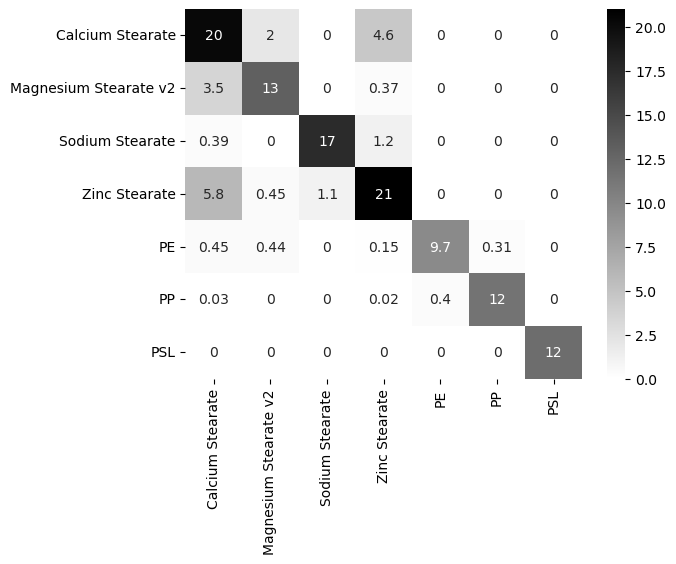

In [20]:
_ = sns.heatmap(mean_mat, 
                #annot=True,
                yticklabels=labels_reb_stearates, 
                xticklabels=labels_reb_stearates,
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':10})
_ = plt.savefig('gloves_contamination/false_negative_analysis/conf_matrix_raman_count.png',bbox_inches='tight')

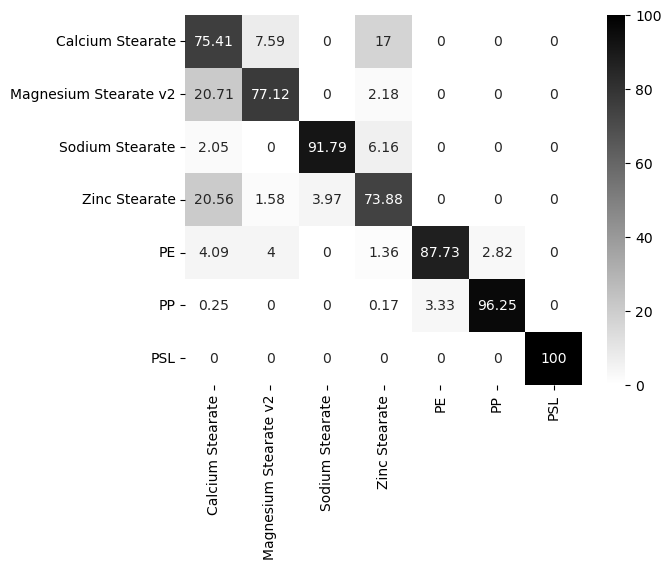

In [21]:
_ = sns.heatmap(np.round(100*mean_mat / mean_mat.sum(1)[:,None], 2), 
                #annot=True,
                yticklabels=labels_reb_stearates, 
                xticklabels=labels_reb_stearates,
                cmap = 'binary',
                annot=True,
                annot_kws={'fontsize':10},
                fmt=".4g",)
_ = plt.savefig('gloves_contamination/false_negative_analysis/conf_matrix_raman_percentage.png',bbox_inches='tight')


In [22]:
df_mat = pd.DataFrame(mean_mat)
df_mat.columns = labels_reb_stearates
df_mat.index = labels_reb_stearates
df_mat.to_csv('gloves_contamination/false_negative_analysis/conf_matrix_raman_count.csv')

,Calcium Stearate,Magnesium Stearate v2,Sodium Stearate,Zinc Stearate,PE,PP,PSL
Calcium Stearate,20.36,2.05,0.00,4.59,0.00,0.00,0.0
Magnesium Stearate v2,3.52,13.11,0.00,0.37,0.00,0.00,0.0
Sodium Stearate,0.39,0.00,17.44,1.17,0.00,0.00,0.0
Zinc Stearate,5.85,0.45,1.13,21.02,0.00,0.00,0.0
PE,0.45,0.44,0.00,0.15,9.65,0.31,0.0
PP,0.03,0.00,0.00,0.02,0.40,11.55,0.0
PSL,0.00,0.00,0.00,0.00,0.00,0.00,12.0


In [24]:
np.round(100*df_mat / df_mat.sum(1)[:,None], 2).to_csv('gloves_contamination/false_negative_analysis/conf_matrix_raman_percentage.csv')


In [28]:
pd.DataFrame({'accuracy':[89.70, 83.14],
              'data':['IR', 'Raman']}).to_csv('gloves_contamination/false_negative_analysis/accuracy.csv')